# Laboratório final com Verificação de Fatos do dataset diponibilizado no kaggle.
 Disponível em: https://www.kaggle.com/competitions/cdp-lab-classificacao-de-notiticas-falsas/overview

# Importando dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!unzip -q '/content/drive/MyDrive/cdp-lab-classificacao-de-notiticas-falsas.zip' >> dataset

## Importando dependências

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords
from nltk.util import ngrams
from collections import Counter
from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
import re

# Análise exploratória

In [ ]:
df = pd.read_csv('train.csv')
df.head()

,title,claim,label,label_encoded
0,É falso que Carlos Bolsonaro recebeu vacina co...,Segundo informações apuradas pela Rádio Litora...,Falso,1
1,"Na Globonews, Tarcísio Motta erra dado históri...",500 mil pessoas passam fome hoje no Rio de Jan...,Verdadeiro,2
2,Paes cumpre metade das 18 promessas do primeir...,"Já no primeiro ano de mandato, estabelecer par...",Falso,1
3,É antigo vídeo atribuído a ato golpista de 8 d...,Brasília hoje dia 08/01/2023 compartilhem,Falso,1
4,É falso aviso sobre golpe ‘cheiro da morte’ pa...,Circula na internet um suposto informativo de ...,Falso,1



Distribuição das classes:
 label
Falso         4024
Verdadeiro     881
Exagerado      370
Name: count, dtype: int64


/tmp/ipython-input-1790060433.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


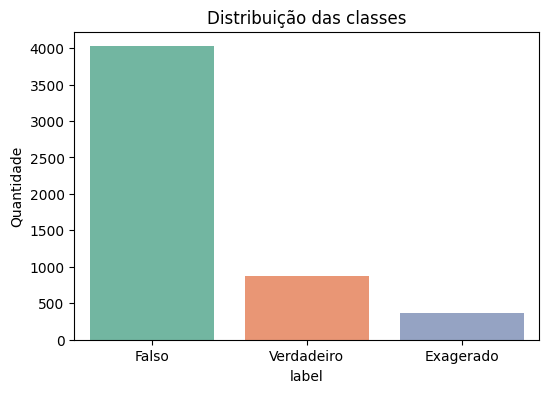

In [ ]:
# Distribuição das classes
class_counts = df['label'].value_counts()
print("\nDistribuição das classes:\n", class_counts)

plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title("Distribuição das classes")
plt.xlabel("label")
plt.ylabel("Quantidade")
plt.show()



Estatísticas de comprimento dos textos:
count    5275.000000
mean       37.626351
std        20.652150
min        11.000000
25%        26.000000
50%        32.000000
75%        43.000000
max       392.000000
Name: text_length, dtype: float64


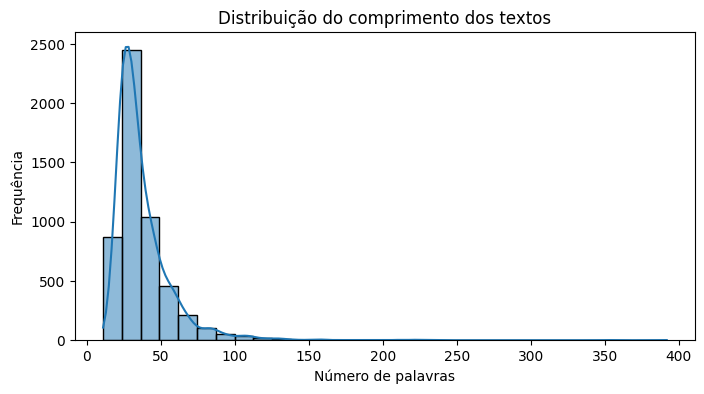

In [ ]:
# Tamanho de título + claim
df['text'] = df['title'] + " " + df['claim']
df['text_length'] = df['text'].apply(lambda x: len(x.split()))

# Estatísticas descritivas dos comprimentos
print("\nEstatísticas de comprimento dos textos:")
print(df['text_length'].describe())

plt.figure(figsize=(8,4))
sns.histplot(df['text_length'], bins=30, kde=True)
plt.title("Distribuição do comprimento dos textos")
plt.xlabel("Número de palavras")
plt.ylabel("Frequência")
plt.show()


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
/tmp/ipython-input-3474524856.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequência', y='Palavra', data=freq_df, palette='coolwarm')


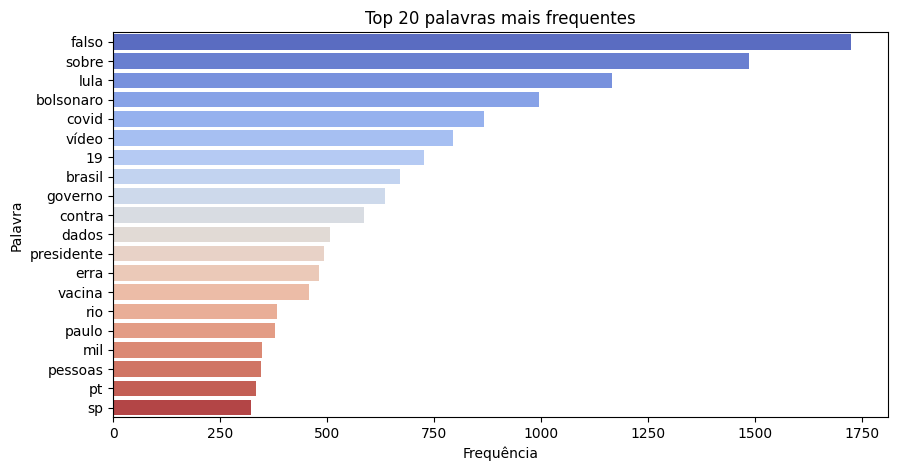

In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

portuguese_stop_words = stopwords.words('portuguese')

# Vetorizando
vectorizer = CountVectorizer(stop_words=portuguese_stop_words, max_features=20)
X = vectorizer.fit_transform(df['text'])

# Frequência das palavras
word_freq = X.toarray().sum(axis=0)
vocab = vectorizer.get_feature_names_out()

freq_df = pd.DataFrame({'Palavra': vocab, 'Frequência': word_freq})
freq_df = freq_df.sort_values(by='Frequência', ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x='Frequência', y='Palavra', data=freq_df, palette='coolwarm')
plt.title("Top 20 palavras mais frequentes")
plt.show()

/tmp/ipython-input-3700622679.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequência', y='Bigram', data=bigram_df, palette='magma')


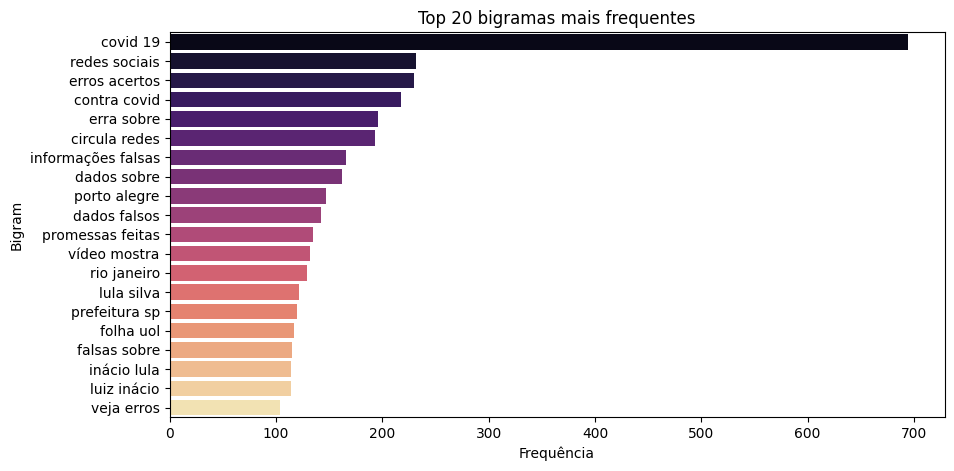

In [ ]:
# Bigramas
vectorizer_2g = CountVectorizer(ngram_range=(2,2), stop_words=portuguese_stop_words, max_features=20)
X2 = vectorizer_2g.fit_transform(df['text'])

bigram_freq = X2.toarray().sum(axis=0)
bigrams = vectorizer_2g.get_feature_names_out()

bigram_df = pd.DataFrame({'Bigram': bigrams, 'Frequência': bigram_freq})
bigram_df = bigram_df.sort_values(by='Frequência', ascending=False)

# Visualização
plt.figure(figsize=(10,5))
sns.barplot(x='Frequência', y='Bigram', data=bigram_df, palette='magma')
plt.title("Top 20 bigramas mais frequentes")
plt.show()

## Visualização de padrões

<ipython-input-9-ff701e6e444a>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='text_length', data=df, palette='Set2')


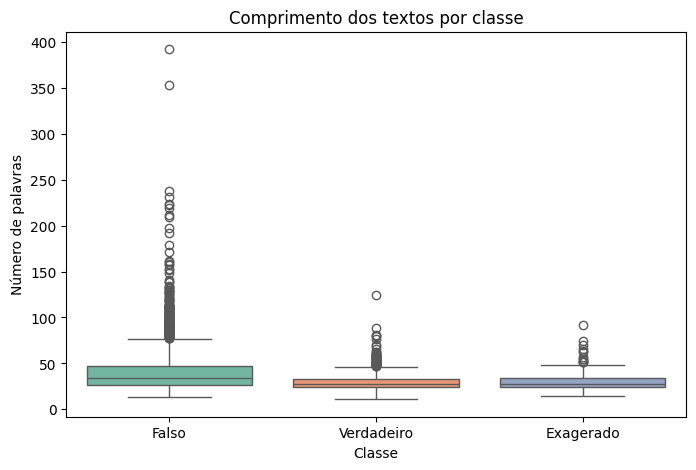

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='text_length', data=df, palette='Set2')
plt.title("Comprimento dos textos por classe")
plt.xlabel("Classe")
plt.ylabel("Número de palavras")
plt.show()


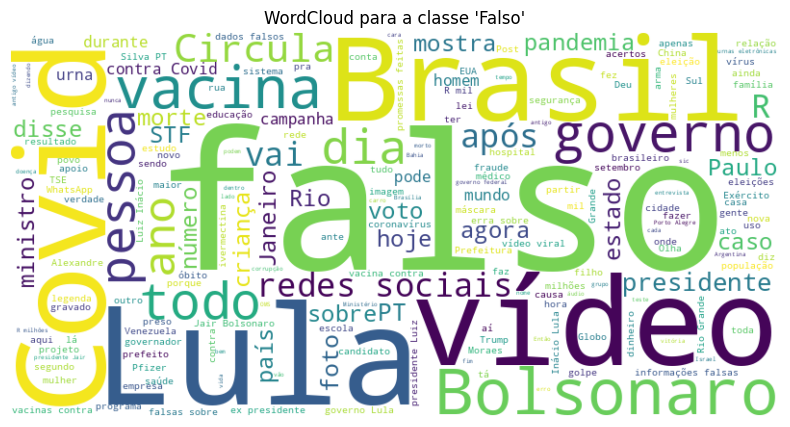

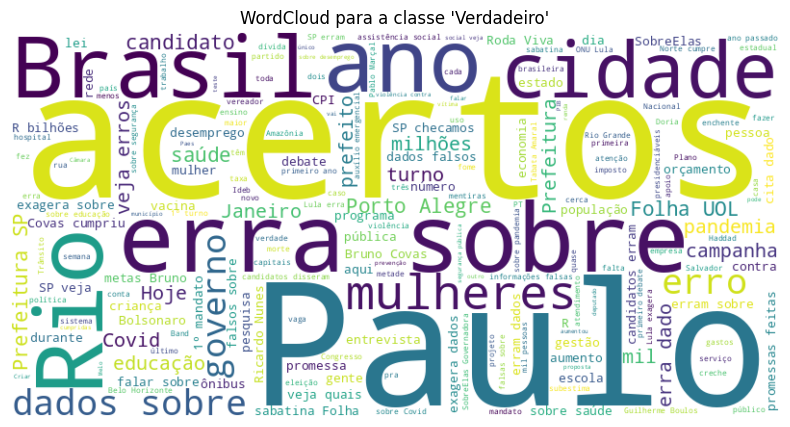

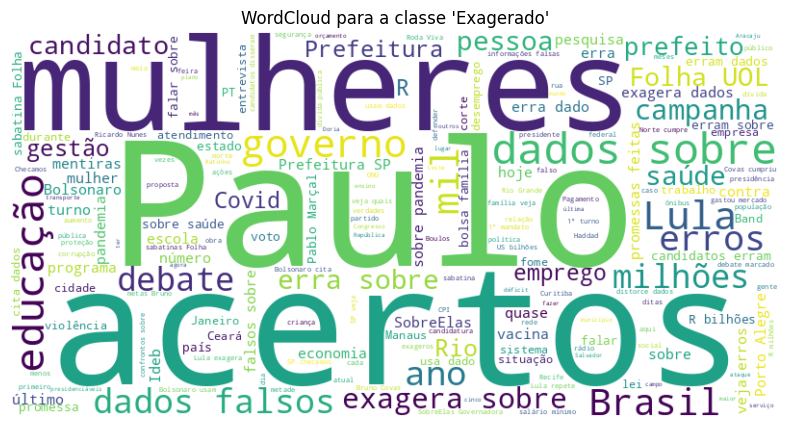

In [ ]:
from wordcloud import WordCloud

## WordCloud para cada uma das labels do dataset
for label in df['label'].unique():
    text = " ".join(df[df['label'] == label]['text'])
    wc = WordCloud(width=800, height=400, background_color='white', stopwords=set(CountVectorizer(stop_words=portuguese_stop_words).get_stop_words())).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"WordCloud para a classe '{label}'")
    plt.show()

# Modelagem

## Pré-processamento textual (tokenização, limpeza, vetorização)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
df["text"] = df["title"] + " " + df["claim"]

def clean_text(text):
    text = re.sub(r"http\S+", "", text)             # remove URLs
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", "", text)       # remove pontuação
    text = text.lower()                              # tudo minúsculo
    return text

df["text_clean"] = df["text"].apply(clean_text)

# Vetorização TF-IDF
vectorizer = TfidfVectorizer(stop_words=portuguese_stop_words, max_features=20000, ngram_range=(1, 2))
X = vectorizer.fit_transform(df["text_clean"])
y = df["label_encoded"]

## Balanceamento de classes

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Checando balanceamento
print("Antes do balanceamento:", Counter(y))

# Aplicando SMOTE para balancear
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Depois do balanceamento:", Counter(y_resampled))


Antes do balanceamento: Counter({1: 4024, 2: 881, 0: 370})
Depois do balanceamento: Counter({1: 4024, 2: 4024, 0: 4024})


## Treinamento dos modelos testados


Treinando modelo: LogisticRegression


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 3 is smaller than n_iter=30. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Melhores parâmetros para LogisticRegression: {'C': 10.0}
Relatório de classificação:
              precision    recall  f1-score   support

   Exagerado       0.95      1.00      0.98       824
       Falso       0.98      0.87      0.92       804
  Verdadeiro       0.91      0.97      0.94       787

    accuracy                           0.95      2415
   macro avg       0.95      0.95      0.95      2415
weighted avg       0.95      0.95      0.95      2415



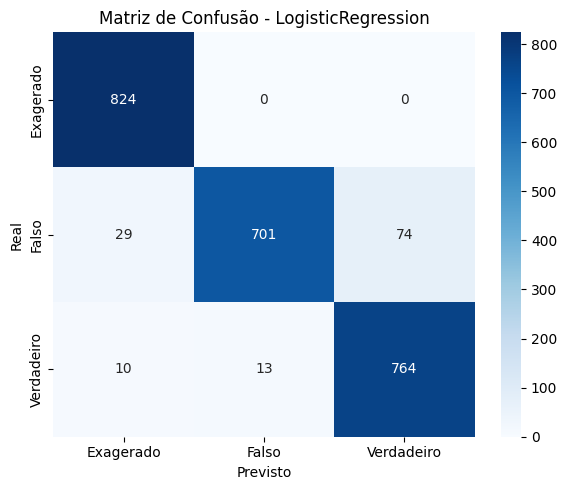

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV

# Separação treino/validação
X_train, X_val, y_train, y_val = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Grid de modelos e parâmetros
models = {
    "LogisticRegression": (LogisticRegression(max_iter=1000), {
        'C': [0.1, 1.0, 10.0]
    }),
}

label_names = ['Exagerado', 'Falso', 'Verdadeiro']

for name, (model, params) in models.items():
    print(f"\nTreinando modelo: {name}")
    search = RandomizedSearchCV(model, params, n_iter=30, cv=3, scoring='f1_macro')
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    y_pred = best_model.predict(X_val)

    print(f"Melhores parâmetros para {name}: {search.best_params_}")
    print("Relatório de classificação:")
    print(classification_report(y_val, y_pred, target_names=label_names))

    # Matriz de confusão
    cm = confusion_matrix(y_val, y_pred)

    # Plot estilizado com seaborn
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
    plt.title(f"Matriz de Confusão - {name}")
    plt.xlabel("Previsto")
    plt.ylabel("Real")
    plt.tight_layout()
    plt.show()

In [ ]:
# Exemplo de novas strings para teste
new_texts = [
    "É falso que o presidente aumentou o salário mínimo em 20%",
    "Governo não anuncia novo programa social para famílias de baixa renda",
    "Covid-19: Vacina pode causar efeitos colaterais graves, diz estudo"
]

# Pré-processar as novas strings (usando as mesmas funções de limpeza e vetorizador TF-IDF)
new_texts_clean = [clean_text(text) for text in new_texts]
X_new = vectorizer.transform(new_texts_clean)

# Fazer previsões
new_predictions_encoded = best_model.predict(X_new)

# Mapear as previsões de volta para os rótulos originais
# Certifique-se de que a ordem dos rótulos aqui corresponde à ordem em label_encoded
label_mapping = {0: 'Exagerado', 1: 'Falso', 2: 'Verdadeiro'}
new_predictions = [label_mapping[pred] for pred in new_predictions_encoded]

# Exibir as previsões
for text, prediction in zip(new_texts, new_predictions):
    print(f"Texto: {text}")
    print(f"Previsão: {prediction}\n")

Texto: É falso que o presidente aumentou o salário mínimo em 20%
Previsão: Falso

Texto: Governo anuncia novo programa social para famílias de baixa renda
Previsão: Falso

Texto: Covid-19: Vacina pode causar efeitos colaterais graves, diz estudo
Previsão: Falso



#Análise dos resultados

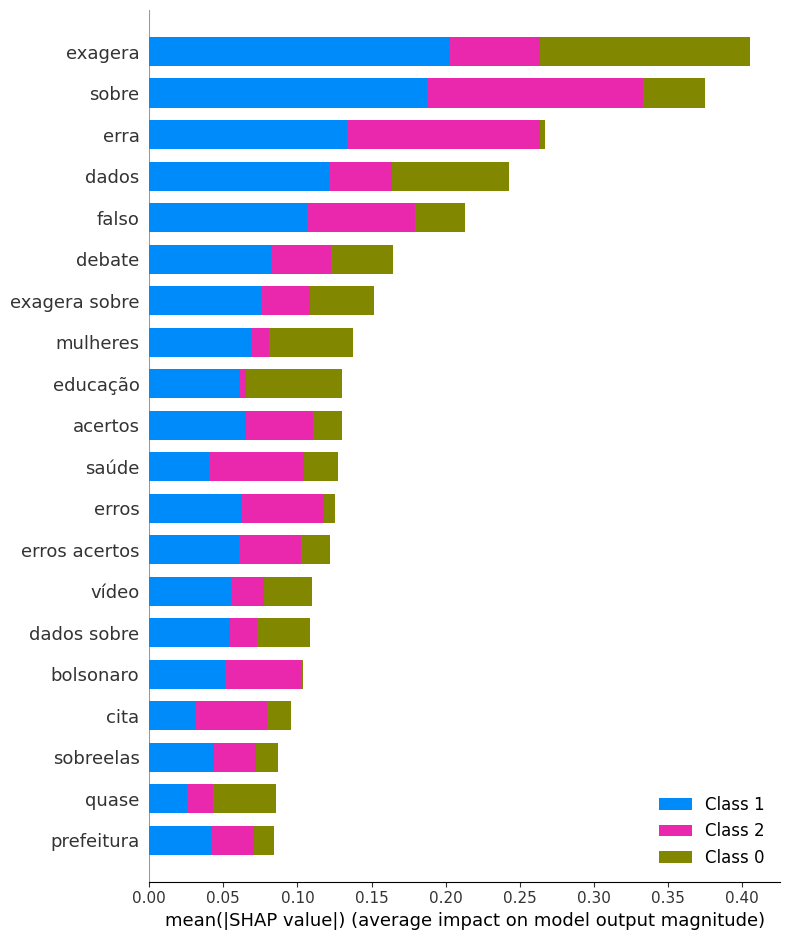

In [ ]:
import shap

# Cria o objeto explainer com o modelo
explainer = shap.Explainer(best_model, X_train)

# Calcula os valores shap para a validação
shap_values = explainer(X_val)
shap.summary_plot(shap_values, X_val, feature_names=vectorizer.get_feature_names_out())


## Interpretação dos termos mais influentes

| Palavra  | Observação |
|----------|------------|
| **exagera** | Fortemente associada à **Classe 1 (Falso)** e **Classe 0 (Exagerado)**. Altamente discriminativa. |
| **sobre**   | Influente para **Classes 1 (Falso)** e **2 (Verdadeiro)**. Palavra genérica, pode estar criando ruído. |
| **erra**    | Associada a **Classes 1 e 2**, mas não à 0. Pode indicar erro factual (**Falso**) ou erro reconhecido (**Verdadeiro**). |
| **falso**   | Esperado que contribua para **Classe 1 (Falso)**. |
| **dados**   | Bastante neutra, mas levemente inclinada para **Classe 1 (Falso)** e **Classe 0 (Exagerado)**. Pode indicar uso impreciso de informações. |

## Discussão sobre as decisões de modelagem

- A forma que o pré-processamento de texto foi feito, combinando title e claim em um único campo e aplicando limpeza, foi uma escolha que busquei para tentar fazer com que o modelo capturasse padrões de uma forma mais completa, além de reduzir o ruído.

- Usar TF-IDF com bigramas e limite de 20.000 features foi uma tentativa de melhorar a classificação de texto. Já que considerei que os bigramas aumentariam a capacidade do modelo de capturar expressões comuns (e.g., “fake news”) e o limite de features ajuda a manter o modelo eficiente sem perder representatividade.

- Quanto aos modelos, tentei escolher modelos bem diferentes entre si para avaliar qual se encaixaria melhor nessa solução:
      - RandomForest é robusto e lida bem com features esparsas.

      - AdaBoost é sensível a ruído, mas pode captar bem padrões com poucos exemplos.

      - LogisticRegression é simples, rápido e geralmente competitivo em problemas lineares.

## Limitações e sugestões de melhorias

- Uma das limitações é que apesar do uso de SMOTE ter equilibrado as classes, ele pode gerar amostras sintéticas que não representam bem a distribuição real dos dados, especialmente em textos vetorizados por TF-IDF.

- Como melhoria, eu aplicaria a análise de erro para identificar padrões nas previsões incorretas e refinar o modelo.

# Gerando arquivo de submissão

In [ ]:
test_df = pd.read_csv("test.csv")

# Pré-processamento igual ao de treino
test_df["text"] = test_df["title"] + " " + test_df["claim"]
test_df["text_clean"] = test_df["text"].apply(clean_text)
X_test = vectorizer.transform(test_df["text_clean"])

# Prever usando o melhor modelo (levando em consideração o F1-score)
best_model = search.best_estimator_
best_model.fit(X_resampled, y_resampled)
y_test_pred = best_model.predict(X_test)

# Criar DataFrame de submissão
submission = pd.DataFrame({
    "id": test_df["id"],
    "label_encoded": y_test_pred
})

# Salvar como CSV
submission.to_csv("submissao.csv", index=False)
print("Arquivo 'submissao.csv' criado com sucesso!")


Arquivo 'submissao.csv' criado com sucesso!
